# 03 · MuJoCo Menagerie tour: the robots of this course

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt

ROBOTS = ["franka_emika_panda", "universal_robots_ur5e", "robotstudio_so101", "aloha",
          "unitree_go2", "unitree_g1", "shadow_hand", "leap_hand", "robotiq_2f85", "kinova_gen3"]

def snapshot(model, data, size=(320, 320), azimuth=135, elevation=-20, scale=1.6):
    cam = mujoco.MjvCamera()
    cam.lookat[:] = model.stat.center
    cam.distance, cam.azimuth, cam.elevation = scale * model.stat.extent, azimuth, elevation
    with mujoco.Renderer(model, *size) as r:
        r.update_scene(data, cam)
        return r.render()

def load(name):
    model = mm.load(name)
    data = mujoco.MjData(model)
    if model.nkey:
        mujoco.mj_resetDataKeyframe(model, data, 0)
    mujoco.mj_forward(model, data)
    return model, data

In [2]:
for name in ROBOTS:
    r = mm.get(name)
    print(f"{r.display_name:28s} {r.category:10s} {r.license:15s} entries={r.entry_names}")

Franka Emika Panda           arm        Apache-2.0      entries=('hand', 'mjx_hand', 'mjx_panda', 'mjx_panda_nohand', 'mjx_scene', 'mjx_single_cube', 'panda', 'panda_nohand', 'scene')
Universal Robots UR5e        arm        BSD-3-Clause    entries=('scene', 'ur5e')
The Robot Studio SO101       arm        Apache-2.0      entries=('scene', 'scene_box', 'so101')
ALOHA                        dual_arm   BSD-3-Clause    entries=('aloha', 'scene')
Unitree Go2                  quadruped  BSD-3-Clause    entries=('go2', 'go2_mjx', 'scene', 'scene_mjx')
Unitree G1                   humanoid   BSD-3-Clause    entries=('g1', 'g1_mjlab', 'g1_mjx', 'g1_with_hands', 'scene', 'scene_mjx', 'scene_with_hands')
Shadow Hand E3M5             end_effector Apache-2.0      entries=('left_hand', 'right_hand', 'scene_left', 'scene_right')
Leap Hand                    end_effector MIT             entries=('left_hand', 'right_hand', 'scene_left', 'scene_right')
Robotiq 2F-85                end_effector BSD-2-Clau

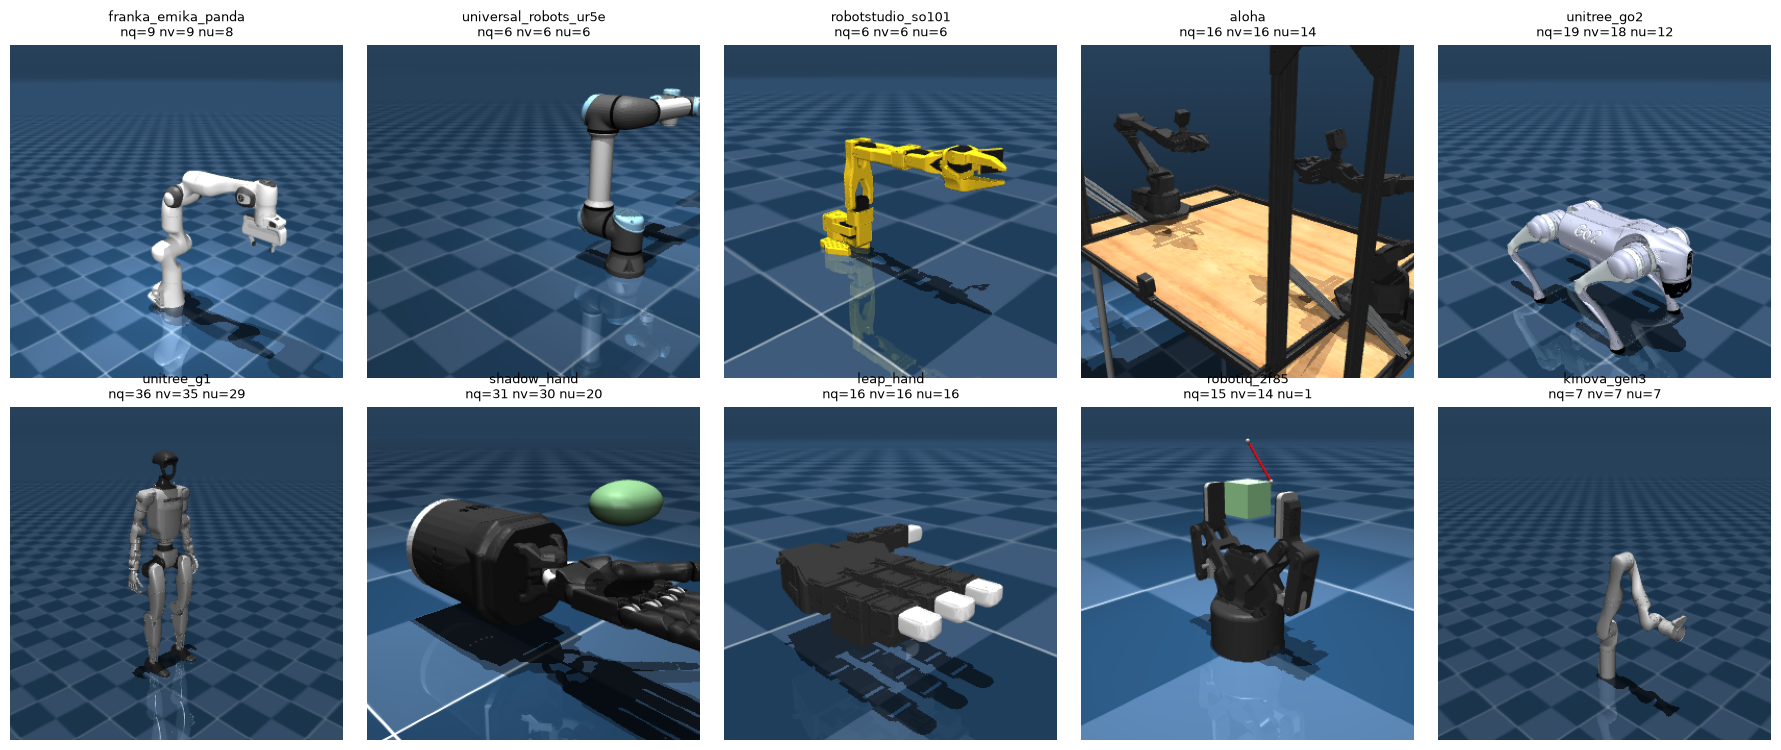

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
for ax, name in zip(axes.flat, ROBOTS):
    model, data = load(name)
    ax.imshow(snapshot(model, data)); ax.axis("off")
    ax.set_title(f"{name}\nnq={model.nq} nv={model.nv} nu={model.nu}", fontsize=9)
plt.tight_layout(); plt.show()

In [4]:
model, data = load("franka_emika_panda")
for j in range(model.njnt):
    print(f"{model.joint(j).name:15s} type={model.jnt_type[j]} range={model.jnt_range[j].round(3)}")
for a in range(model.nu):
    print(f"{model.actuator(a).name:12s} ctrlrange={model.actuator_ctrlrange[a].round(3)}")

joint1          type=3 range=[-2.897  2.897]
joint2          type=3 range=[-1.763  1.763]
joint3          type=3 range=[-2.897  2.897]
joint4          type=3 range=[-3.072 -0.07 ]
joint5          type=3 range=[-2.897  2.897]
joint6          type=3 range=[-0.018  3.752]
joint7          type=3 range=[-2.897  2.897]
finger_joint1   type=2 range=[0.   0.04]
finger_joint2   type=2 range=[0.   0.04]
actuator1    ctrlrange=[-2.897  2.897]
actuator2    ctrlrange=[-1.763  1.763]
actuator3    ctrlrange=[-2.897  2.897]
actuator4    ctrlrange=[-3.072 -0.07 ]
actuator5    ctrlrange=[-2.897  2.897]
actuator6    ctrlrange=[-0.018  3.752]
actuator7    ctrlrange=[-2.897  2.897]
actuator8    ctrlrange=[  0. 255.]
